# **Lab 5: Finding Motor Parameters**

### **Adhambek Yashnarbekov, ID 240062**

<p>I followed the experimental setup described in the Lab 5 README. I lifted the robot off the ground and ran the program `motor_identification.qrs` on both wheels.
* The left wheel uses motor M4 and encoder E4.
* The right wheel uses motor M3 and encoder E3.

The test program changes the motor power (PWM) from -100% to +100% in steps of 5%. For each step, the motor runs for 2 seconds and then stays off for 1 second. During this time, the program continuously records the wheel angle, timestamps, and the current PWM percentage to a file. The battery voltage remained stable at 11.2V throughout the entire experiment.

To process this data, I followed the course notebook `Motor_identification.ipynb`. Please upload the data files `steps5_M4.txt` and `steps5_M3.txt` in the cell below.</p>

In [8]:
from google.colab import files    # file work module
uploaded = files.upload()         # upload file context window

Saving steps5_M3.txt to steps5_M3 (1).txt
Saving steps5_M4.txt to steps5_M4 (1).txt


In [9]:
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization
from scipy import optimize          # data fitting
from scipy.integrate import odeint  # ordinary differential equation solver
import pandas as pd                 # tables

## 1. Finding $T_m$ and $\omega_{ss}$ for each PWM Level

For each PWM step, I read the corresponding lines from the data file. I converted the time to seconds and the angle to radians, starting both from zero. Then, I fit the theoretical model to our experimental data using `curve_fit`:

$\theta(t) = \omega_{ss}(t - T_m + T_m e^{-t/T_m})$

I added strict boundaries to `curve_fit` for $T_m$ (between 0.005 and 2 seconds). This was necessary because without these limits, the calculation for the right wheel at 100% power gave incorrect results.

The voltage is calculated as: $U = \text{PWM}/100 \cdot U_{\text{battery}}$ (where $U_{\text{battery}} = 11.2\text{ V}$).

The tables below show the calculated steady-state speed ($\omega_{ss}$) and time constant ($T_m$) for each PWM level for both wheels.

In [10]:
U_battery = 11.2

def model(t, w_ss, T_m):
    return w_ss * (t - T_m + T_m * np.exp(-t / T_m))

def fit_file(name):
    angle, time, pwm = np.loadtxt(name, delimiter=',', unpack=True)
    time = time / 1000                  # SI conversion
    angle = angle * np.pi / 180         # SI conversion
    results = []
    for level in np.unique(pwm):
        if level == 0:
            continue
        t = time[pwm == level] - time[pwm == level][0]
        theta = angle[pwm == level] - angle[pwm == level][0]
        popt, pcov = optimize.curve_fit(model, t, theta, p0=[8, 0.1], bounds=([-60, 0.005], [60, 2]))
        results.append([level, popt[0], popt[1]])
    return np.array(results)

left = fit_file('steps5_M4.txt')
right = fit_file('steps5_M3.txt')

for res, name in [(left, 'Left wheel (M4)'), (right, 'Right wheel (M3)')]:
    table = pd.DataFrame({'PWM, %': res[:, 0],
                          'U, V': res[:, 0] / 100 * U_battery,
                          'w_ss, rad/s': res[:, 1],
                          'T_m, s': res[:, 2]})
    print(name)
    print(table.round(3))

Left wheel (M4)
    PWM, %   U, V  w_ss, rad/s  T_m, s
0   -100.0 -11.20      -13.812   0.033
1    -95.0 -10.64      -13.310   0.046
2    -90.0 -10.08      -12.484   0.074
3    -85.0  -9.52      -11.748   0.095
4    -80.0  -8.96      -11.393   0.104
5    -75.0  -8.40      -10.970   0.114
6    -70.0  -7.84      -10.221   0.126
7    -65.0  -7.28       -9.427   0.168
8    -60.0  -6.72       -9.152   0.166
9    -55.0  -6.16       -8.560   0.175
10   -50.0  -5.60       -8.233   0.190
11   -45.0  -5.04       -7.829   0.200
12   -40.0  -4.48       -7.402   0.190
13   -35.0  -3.92       -7.077   0.202
14   -30.0  -3.36       -6.022   0.224
15   -25.0  -2.80       -5.391   0.224
16   -20.0  -2.24       -4.735   0.261
17   -15.0  -1.68       -4.283   0.005
18   -10.0  -1.12       -3.298   0.291
19    -5.0  -0.56       -1.255   0.324
20     5.0   0.56        1.252   0.208
21    10.0   1.12        3.657   0.312
22    15.0   1.68        4.600   0.335
23    20.0   2.24        5.384   0.282
24    25.

At +5% PWM on the left wheel, the fitting failed because $T_m$ hit the lower limit of 0.005 seconds. This happened because the wheel jerked forward suddenly and then slowed down right away.

left (M4): k_e = 0.720 V*s/rad
right (M3): k_e = 0.661 V*s/rad


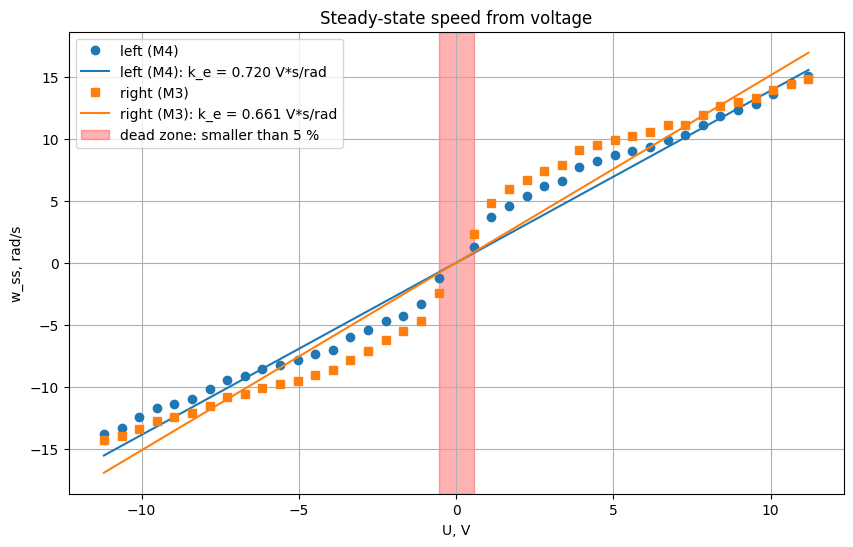

In [11]:
## 2. Motor Speed vs. Applied Voltage

According to our theoretical model, the steady-state speed is directly proportional to the voltage: $\omega_{ss} = U / k_e$.

For each wheel, I fit this linear model to all data points using `curve_fit` to find the motor constant $k_e$. Since both wheels start rotating even at a low ±5% PWM, the motor dead zone is very small (less than 5%). I have highlighted this dead zone in red on the plot below (between -5% and +5% of battery voltage).

## 3. Time Constant ($T_m$) vs. Applied Voltage

According to the physical model, the time constant $T_m = J R / (k_e k_m)$ depends only on internal motor properties: the moment of inertia ($J$), electrical resistance ($R$), and motor constants ($k_e$ and $k_m$). Therefore, $T_m$ should remain constant regardless of the voltage.

To verify this assumption, I plotted the calculated $T_m$ values against the applied voltage.

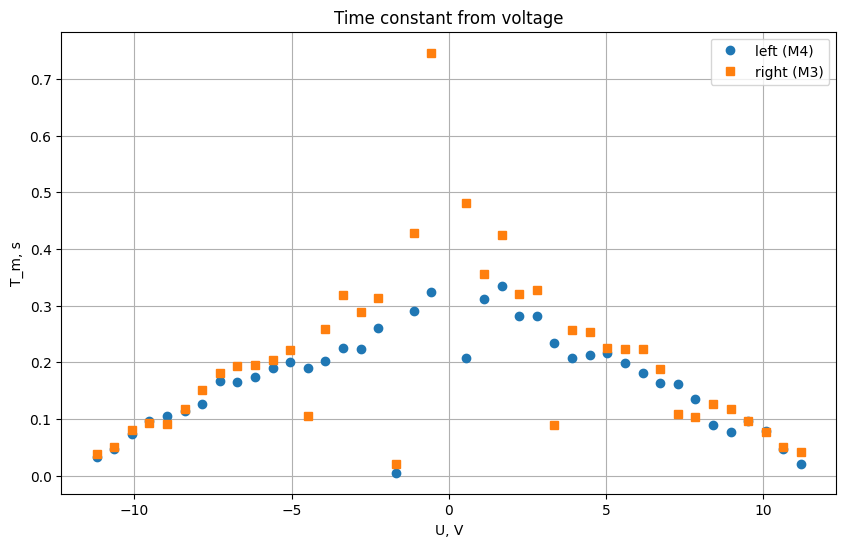

In [12]:
plt.figure(figsize=(10, 6), dpi=100)
for res, name, mark in [(left, 'left (M4)', 'o'), (right, 'right (M3)', 's')]:
    U = res[:, 0] / 100 * U_battery
    plt.plot(U, res[:, 2], mark, label=name)
plt.xlabel('U, V')
plt.ylabel('T_m, s')
plt.title('Time constant from voltage')
plt.grid()
plt.legend()
plt.show()

As we can see, the time constant $T_m$ is not actually constant.

For both wheels, $T_m$ is around 0.3 to 0.6 seconds at low voltages, but drops to about 0.05 seconds at full power (±11.2 V). This is likely because the motor has to overcome friction. At low voltages, the motor force is barely stronger than friction, making the wheel speed up very slowly (which our friction-free model doesn't account for). At high voltages, the wheel speeds up incredibly fast (in about 50 ms). Since our measurements are taken 20 ms apart, we only get 2 or 3 data points during this quick acceleration phase, making the $T_m$ calculation at high power less precise.

The outlying low points for the left wheel are due to the failed fit at +5% PWM, and anomalies at +30% and +55% PWM where the wheel started moving much faster than during neighboring test steps.

## 4. Comparing Simulation and Real Measurement for One Step

Here, we look at a single step-response (the +50% PWM step for the left wheel). I simulated this using the `motor` model and `odeint` solver from the course materials, using the fitted $T_m$ and $k_e$ values specific to this step.

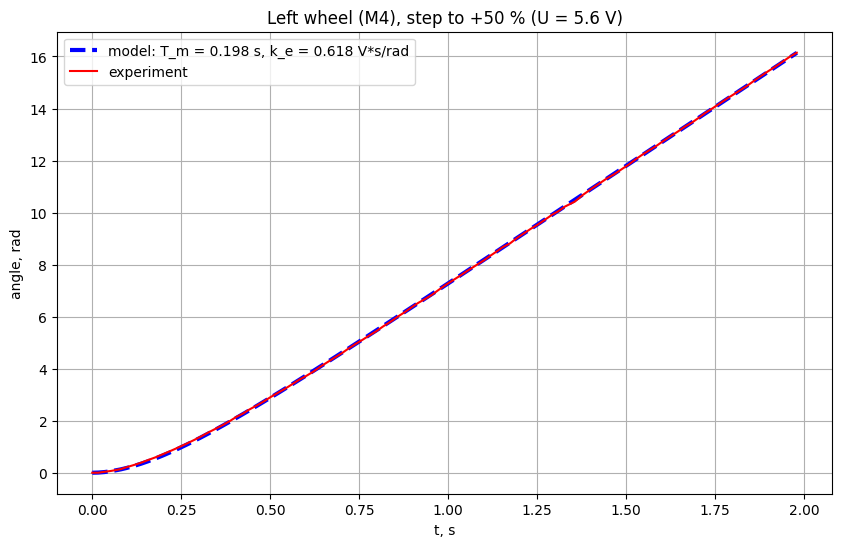

In [13]:
def motor(state, t):
    speed, angle = state                                            # motor state space
    state_dt = np.array([-speed/T_m + u/ (T_m * k_e), speed ])      # differential equation for the motor state
    return state_dt

angle, time, pwm = np.loadtxt('steps5_M4.txt', delimiter=',', unpack=True)
time = (time[pwm == 50] - time[pwm == 50][0]) / 1000            # SI conversion
angle = (angle[pwm == 50] - angle[pwm == 50][0]) * np.pi / 180  # SI conversion
popt, pcov = optimize.curve_fit(model, time, angle, p0=[8, 0.1])

T_m = popt[1]                                                   # electromechanical time constant
u = 50 / 100 * U_battery                                        # voltage at 50 %
k_e = u / popt[0]                                               # k_e = U / w_ss
init = [0, 0]                                                   # initial speed and angle
y = odeint(motor, init, time)                                   # numerical ode solution

plt.figure(figsize=(10, 6), dpi=100)
plt.plot(time, y[:, 1], 'b--', linewidth=3, label=f'model: T_m = {T_m:.3f} s, k_e = {k_e:.3f} V*s/rad')
plt.plot(time, angle, 'r-', linewidth=1.5, label='experiment')
plt.xlabel('t, s')
plt.ylabel('angle, rad')
plt.title('Left wheel (M4), step to +50 % (U = 5.6 V)')
plt.grid()
plt.legend()
plt.show()

## 5. Summary and Conclusions

1. **Model Limitations:** The simple linear model $\omega_{ss} = U / k_e$ is inaccurate at low PWM values. In reality, the wheels spin 2 to 3 times faster at low power than the model predicts. For example, at 10% PWM, the left wheel actually spins at 3.7 rad/s, while the model estimates only 1.6 rad/s.
2. **Variable Time Constant:** The electromechanical time constant $T_m$ is not constant. It ranges from 0.3–0.6 seconds at low PWM down to 0.05 seconds at 100% PWM.
3. **Dead Zone:** The dead zone is tiny (under 5% PWM) because the wheels start spinning immediately at the first 5% step.
4. **Asymmetry:** The right wheel is faster than the left wheel at low and medium power (it is 30% faster at 10% PWM, and 12% faster at 50% PWM). However, they reach almost the same speed at 100% power. This means the right motor has a smaller constant $k_e$ (0.66 V·s/rad) compared to the left motor (0.71 V·s/rad).
5. **Impact on Future Work:** Because the motors behave differently, the robot will not drive in a straight line if we give both motors the exact same PWM signal; it will drift to the left. To track movement accurately (odometry), we must rely on the individual wheel encoder angles rather than assuming speed based on PWM.